In [1]:
import os
import numpy as np
import glob
import PIL.Image as Image

# pip install torchsummary
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision import models
from torchsummary import summary
import torch.optim as optim
from time import time

import matplotlib.pyplot as plt
from IPython.display import clear_output
from sklearn.model_selection import train_test_split

In [2]:
 # This is for running the notebook on CoLab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# This is for running the notebook on CoLab

path_ph2 = 'drive/MyDrive/PH2_Dataset_images'
# path_ph2 = r'C:/Users/Frederik\Downloads/PH2_Dataset_images'


In [ ]:
# This is for running the notebook on HPC

#path_ph2 = r"/dtu/datasets1/02516/PH2_Dataset_images"

In [38]:
# check if cuda active
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [49]:
import torch
import numpy as np
from enum import Enum
from typing import Tuple, List, Union, Dict
from scipy.ndimage import distance_transform_edt, binary_erosion, binary_dilation
import cv2

class SamplingStrategy(Enum):
    RANDOM = "random"
    DISTANCE_TRANSFORM = "distance_transform"
    BOUNDARY_AWARE = "boundary_aware"
    UNCERTAINTY = "uncertainty"

class AnnotationType(Enum):
    POINTS = "points"
    SCRIBBLES = "scribbles"
    BOXES = "boxes"
    EXTREME_POINTS = "extreme_points"

class WeakAnnotationGenerator:
    def __init__(
        self,
        sampling_strategy: SamplingStrategy = SamplingStrategy.RANDOM,
        min_object_size: int = 100,
        scribble_length: int = 30,
        scribble_thickness: int = 2
    ):
        self.sampling_strategy = sampling_strategy
        self.min_object_size = min_object_size
        self.scribble_length = scribble_length
        self.scribble_thickness = scribble_thickness

    def generate_annotations(
        self,
        mask: torch.Tensor,
        annotation_type: AnnotationType,
        num_positive: int = 3,
        num_negative: int = 3,
        uncertainty_map: torch.Tensor = None
    ) -> Dict[str, torch.Tensor]:
        if annotation_type == AnnotationType.POINTS:
            return self._generate_points(mask, num_positive, num_negative, uncertainty_map)
        elif annotation_type == AnnotationType.SCRIBBLES:
            return self._generate_scribbles(mask, num_positive, num_negative)
        elif annotation_type == AnnotationType.BOXES:
            return self._generate_boxes(mask)
        elif annotation_type == AnnotationType.EXTREME_POINTS:
            return self._generate_extreme_points(mask)
        else:
            raise ValueError(f"Unknown annotation type: {annotation_type}")

    def _sample_points(
      self,
      valid_regions: np.ndarray,
      num_points: int,
      uncertainty_map: torch.Tensor = None
    ) -> np.ndarray:
      if valid_regions.sum() == 0:
        return np.zeros((0, 2), dtype=np.int64)

      H, W = valid_regions.shape
      valid_indices = np.where(valid_regions)

      if len(valid_indices[0]) == 0:
        return np.zeros((0, 2), dtype=np.int64)

      # Ensure num_points is integer
      num_points = int(num_points)

      indices = np.random.choice(len(valid_indices[0]),
                             size=min(num_points, len(valid_indices[0])),
                             replace=len(valid_indices[0]) < num_points)

      # Explicitly convert to integers
      points = np.stack([
        valid_indices[0][indices].astype(np.int64),
        valid_indices[1][indices].astype(np.int64)
      ], axis=1)

      return points

    def _generate_points(
        self,
        mask: torch.Tensor,
        num_positive: int,
        num_negative: int,
        uncertainty_map: torch.Tensor = None
    ) -> Dict[str, torch.Tensor]:

        mask_np = (mask.cpu().numpy() > 0.5).astype(np.int32)  # Adding threshold and int conversion
        valid_positive = mask_np > 0
        valid_negative = mask_np == 0

        positive_points = self._sample_points(valid_positive, num_positive, uncertainty_map)
        negative_points = self._sample_points(valid_negative, num_negative, uncertainty_map)

        return {
        'positive_points': torch.tensor(positive_points, dtype=torch.long),
        'negative_points': torch.tensor(negative_points, dtype=torch.long)
        }

    def _generate_boxes(self, mask: torch.Tensor) -> Dict[str, torch.Tensor]:
        mask_np = mask.cpu().numpy().astype(np.uint8)
        mask_np = (mask_np > 0).astype(np.uint8)
        ret, labeled_mask = cv2.connectedComponents(mask_np)
        boxes = []

        for label in range(1, ret):
            obj_mask = (labeled_mask == label)
            if np.sum(obj_mask) < self.min_object_size:
                continue
            coords = np.where(obj_mask)
            if len(coords[0]) > 0:
                y_min, y_max = np.min(coords[0]), np.max(coords[0])
                x_min, x_max = np.min(coords[1]), np.max(coords[1])
                boxes.append([x_min, y_min, x_max, y_max])

        return {
            'boxes': torch.tensor(boxes, dtype=torch.long) if boxes else torch.zeros((0, 4), dtype=torch.long)
        }

    def _generate_extreme_points(self, mask: torch.Tensor) -> Dict[str, torch.Tensor]:
        mask_np = mask.cpu().numpy().astype(np.uint8)
        labeled_mask, num_objects = cv2.connectedComponents(mask_np)
        extreme_points_list = []

        for obj_id in range(1, num_objects):
            obj_mask = labeled_mask == obj_id
            if obj_mask.sum() < self.min_object_size:
                continue
            y_indices, x_indices = np.where(obj_mask)
            extreme_points = np.array([
                [y_indices[x_indices.argmin()], x_indices.min()],  # leftmost
                [y_indices[x_indices.argmax()], x_indices.max()],  # rightmost
                [y_indices.min(), x_indices[y_indices.argmin()]],  # topmost
                [y_indices.max(), x_indices[y_indices.argmax()]]   # bottommost
            ])
            extreme_points_list.append(extreme_points)

        return {
            'extreme_points': torch.tensor(extreme_points_list, dtype=torch.long) if extreme_points_list
                            else torch.zeros((0, 4, 2), dtype=torch.long)
        }

    def _generate_scribbles(
        self,
        mask: torch.Tensor,
        num_positive: int,
        num_negative: int
    ) -> Dict[str, torch.Tensor]:
        mask_np = mask.cpu().numpy()
        H, W = mask_np.shape
        scribble_mask = np.zeros((H, W), dtype=np.uint8)

        # Generate positive scribbles
        valid_positive = mask_np > 0
        start_points = self._sample_points(valid_positive, num_positive)

        for start_point in start_points:
            angle = np.random.uniform(0, 2 * np.pi)
            end_point = [
                int(start_point[0] + self.scribble_length * np.sin(angle)),
                int(start_point[1] + self.scribble_length * np.cos(angle))
            ]
            end_point = [
                min(max(0, end_point[0]), H-1),
                min(max(0, end_point[1]), W-1)
            ]
            cv2.line(scribble_mask,
                    (start_point[1], start_point[0]),
                    (end_point[1], end_point[0]),
                    1,
                    self.scribble_thickness)

        # Generate negative scribbles
        valid_negative = mask_np == 0
        start_points = self._sample_points(valid_negative, num_negative)

        for start_point in start_points:
            angle = np.random.uniform(0, 2 * np.pi)
            end_point = [
                int(start_point[0] + self.scribble_length * np.sin(angle)),
                int(start_point[1] + self.scribble_length * np.cos(angle))
            ]
            end_point = [
                min(max(0, end_point[0]), H-1),
                min(max(0, end_point[1]), W-1)
            ]
            cv2.line(scribble_mask,
                    (start_point[1], start_point[0]),
                    (end_point[1], end_point[0]),
                    2,
                    self.scribble_thickness)

        return {
            'scribble_mask': torch.tensor(scribble_mask, dtype=torch.long)
        }

def visualize_annotations(
    image: torch.Tensor,
    annotations: Dict[str, torch.Tensor],
    annotation_type: AnnotationType,
    color_map: Dict[str, Tuple[float, float, float]] = None
) -> torch.Tensor:
    """
    Visualize different types of weak annotations on an image.

    Args:
        image: Input image tensor of shape (C, H, W) or (H, W)
        annotations: Dictionary containing different types of annotations
        annotation_type: Type of annotations (POINTS, SCRIBBLES, BOXES, EXTREME_POINTS)
        color_map: Optional dictionary mapping annotation types to RGB colors
                  Default colors: positive (green), negative (red), boxes/extreme points (blue)

    Returns:
        visualization: Tensor of shape (3, H, W) with annotations overlaid
    """
    # Default color map
    if color_map is None:
        color_map = {
            'positive': (0.0, 1.0, 0.0),  # Green
            'negative': (1.0, 0.0, 0.0),  # Red
            'box': (0.0, 0.0, 1.0),       # Blue
            'extreme': (1.0, 1.0, 0.0)     # Yellow
        }

    # Ensure image is 3-channel
    vis = image.clone()
    if vis.dim() == 2:
        vis = vis.unsqueeze(0).repeat(3, 1, 1)
    elif vis.dim() == 3 and vis.shape[0] == 1:
        vis = vis.repeat(3, 1, 1)

    if annotation_type == AnnotationType.POINTS:
        # Draw positive points
        if 'positive_points' in annotations:
            for y, x in annotations['positive_points']:
                y, x = int(y), int(x)
                for c, v in enumerate(color_map['positive']):
                    vis[c, max(0, y-2):min(vis.shape[1], y+3),
                        max(0, x-2):min(vis.shape[2], x+3)] = v

        # Draw negative points
        if 'negative_points' in annotations:
            for y, x in annotations['negative_points']:
                y, x = int(y), int(x)
                for c, v in enumerate(color_map['negative']):
                    vis[c, max(0, y-2):min(vis.shape[1], y+3),
                        max(0, x-2):min(vis.shape[2], x+3)] = v

    elif annotation_type == AnnotationType.SCRIBBLES:
        if 'scribble_mask' in annotations:
            scribble_mask = annotations['scribble_mask']
            # Positive scribbles (value 1)
            for c, v in enumerate(color_map['positive']):
                vis[c, scribble_mask == 1] = v
            # Negative scribbles (value 2)
            for c, v in enumerate(color_map['negative']):
                vis[c, scribble_mask == 2] = v

    elif annotation_type == AnnotationType.BOXES:
        if 'boxes' in annotations:
            thickness = 2
            for box in annotations['boxes']:
                x_min, y_min, x_max, y_max = map(int, box)
                # Draw horizontal lines
                for c, v in enumerate(color_map['box']):
                    vis[c, y_min:y_min+thickness, x_min:x_max+1] = v  # Top
                    vis[c, y_max-thickness+1:y_max+1, x_min:x_max+1] = v  # Bottom
                    vis[c, y_min:y_max+1, x_min:x_min+thickness] = v  # Left
                    vis[c, y_min:y_max+1, x_max-thickness+1:x_max+1] = v  # Right

    elif annotation_type == AnnotationType.EXTREME_POINTS:
        if 'extreme_points' in annotations:
            for points in annotations['extreme_points']:
                for point in points:
                    y, x = map(int, point)
                    for c, v in enumerate(color_map['extreme']):
                        vis[c, max(0, y-2):min(vis.shape[1], y+3),
                            max(0, x-2):min(vis.shape[2], x+3)] = v

    return vis

In [40]:
# Dataloader for the ph2 dataset
class PH2_Dataloader(torch.utils.data.Dataset):
    def __init__(self, image_paths, mask_paths, transform_image=None, transform_mask=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform_image = transform_image
        self.transform_mask = transform_mask

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx])
        mask = Image.open(self.mask_paths[idx])

        if self.transform_image and self.transform_mask:
            # Apply the same transformation to both image and mask
            seed = torch.seed()  # Set random seed so same transformation is applied to both
            torch.manual_seed(seed)
            image = self.transform_image(image)
            torch.manual_seed(seed)
            mask = self.transform_mask(mask)

        else:
            # If no transforms are provided, at least convert to tensor
            image = transforms.Resize((size, size))(image)
            mask = transforms.Resize((size, size))(mask)
            image = transforms.ToTensor()(image)
            mask = transforms.ToTensor()(mask)

        return image, mask

size = 256 ## wanted to use 256 but testing was too slow on local PC.
batch_size = 6
num_workers = 0 # Should be higher when running on HPC.

image_paths = sorted(glob.glob(os.path.join(path_ph2, "IMD*","IMD*_Dermoscopic_Image",'*.bmp')))
mask_paths = sorted(glob.glob(os.path.join(path_ph2, "IMD*","IMD*_lesion", '*.bmp')))

image_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomResizedCrop((size, size), antialias=True),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])

mask_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomResizedCrop((size, size), antialias=True),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
])

# For validation/test
test_val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
])

def binary_mask_from_weak_annotations(image_shape, weak_annotations):
    binary_mask = torch.zeros(image_shape[1:], dtype=torch.float32)  # Shape: (height, width)

    positive_points = weak_annotations['positive_points']
    negative_points = weak_annotations['negative_points']

    # Set positive points to 1
    for point in positive_points.tolist():
        x, y = point
        if 0 <= x < binary_mask.shape[0] and 0 <= y < binary_mask.shape[1]:
            binary_mask[x, y] = 1

    # Optionally set negative points to 0 (not needed since mask is already initialized to 0)
    for point in negative_points.tolist():
        x, y = point
        if 0 <= x < binary_mask.shape[0] and 0 <= y < binary_mask.shape[1]:
            binary_mask[x, y] = 0

    return binary_mask



# First, split into 80% train and 20% val+test
train_img_paths, val_test_img_paths, train_mask_paths, val_test_mask_paths = train_test_split(
    image_paths, mask_paths, test_size=0.2, random_state=42)

# Split the remaining 20% into validation and test
val_img_paths, test_img_paths, val_mask_paths, test_mask_paths = train_test_split(
    val_test_img_paths, val_test_mask_paths, test_size=0.5, random_state=42)

trainset = PH2_Dataloader(image_paths=train_img_paths, mask_paths=train_mask_paths, transform_image=image_transform, transform_mask=mask_transform)
valset = PH2_Dataloader(image_paths=val_img_paths, mask_paths=val_mask_paths, transform_image=test_val_transform , transform_mask=test_val_transform)
testset = PH2_Dataloader(image_paths=test_img_paths, mask_paths=test_mask_paths, transform_image=test_val_transform)

train_loader_ph2 = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader_ph2 = DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader_ph2 = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

In [41]:
train_loader = train_loader_ph2
val_loader = val_loader_ph2
test_loader = test_loader_ph2

In [42]:
# I made the UNet less procedural to make fixing errors easier

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 0, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, 1, 0, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

        #self.apply(self._init_weights)

    def forward(self, x):
        return self.conv(x)

class UNET(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNET, self).__init__()

        # Encoder path
        self.conv1 = DoubleConv(in_channels, 64)
        self.conv2 = DoubleConv(64, 128)
        self.conv3 = DoubleConv(128, 256)
        self.conv4 = DoubleConv(256, 512)
        self.pool = nn.AvgPool2d(2, 2)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # Decoder path
        # Replace transposed convolutions with 1x1 convs for channel reduction
        self.upconv4 = nn.Conv2d(1024, 512, 1)
        self.dconv4 = DoubleConv(1024, 512)  # Input channels doubled due to concatenation
        self.upconv3 = nn.Conv2d(512, 256, 1)
        self.dconv3 = DoubleConv(512, 256)
        self.upconv2 = nn.Conv2d(256, 128, 1)
        self.dconv2 = DoubleConv(256, 128)
        self.upconv1 = nn.Conv2d(128, 64, 1)
        self.dconv1 = DoubleConv(128, 64)

        # Bilinear upsampling
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # Final convolution
        self.final_conv = nn.Conv2d(64, out_channels, 1)

    def forward(self, x):
        # Encoder path
        conv1 = self.conv1(x)
        x = self.pool(conv1)

        conv2 = self.conv2(x)
        x = self.pool(conv2)

        conv3 = self.conv3(x)
        x = self.pool(conv3)

        conv4 = self.conv4(x)
        x = self.pool(conv4)

        # Bottleneck
        x = self.bottleneck(x)

        # Decoder path with skip connections
        x = self.upconv4(x)
        x = self.upsample(x)
        diffY = conv4.size()[2] - x.size()[2]
        diffX = conv4.size()[3] - x.size()[3]
        conv4_cropped = conv4[:, :,
                      diffY // 2: (diffY // 2 + x.size()[2]),
                      diffX // 2: (diffX // 2 + x.size()[3])]
        x = self.dconv4(torch.cat([conv4_cropped, x], 1))

        x = self.upconv3(x)
        x = self.upsample(x)
        diffY = conv3.size()[2] - x.size()[2]
        diffX = conv3.size()[3] - x.size()[3]
        conv3_cropped = conv3[:, :,
                      diffY // 2: (diffY // 2 + x.size()[2]),
                      diffX // 2: (diffX // 2 + x.size()[3])]
        x = self.dconv3(torch.cat([conv3_cropped, x], 1))

        x = self.upconv2(x)
        x = self.upsample(x)
        diffY = conv2.size()[2] - x.size()[2]
        diffX = conv2.size()[3] - x.size()[3]
        conv2_cropped = conv2[:, :,
                      diffY // 2: (diffY // 2 + x.size()[2]),
                      diffX // 2: (diffX // 2 + x.size()[3])]
        x = self.dconv2(torch.cat([conv2_cropped, x], 1))

        x = self.upconv1(x)
        x = self.upsample(x)
        diffY = conv1.size()[2] - x.size()[2]
        diffX = conv1.size()[3] - x.size()[3]
        conv1_cropped = conv1[:, :,
                      diffY // 2: (diffY // 2 + x.size()[2]),
                      diffX // 2: (diffX // 2 + x.size()[3])]
        x = self.dconv1(torch.cat([conv1_cropped, x], 1))

        return self.final_conv(x)

    def calculate_output_size(self, input_size):
        """Calculate output size given input size (helpful for zero padding)"""
        def conv_output_size(input_size):
            return input_size - 4  # Loses 2 pixels on each side twice

        def pool_output_size(input_size):
            return input_size // 2

        size = input_size
        # Encoder path
        size = conv_output_size(size)  # conv1
        size = pool_output_size(size)
        size = conv_output_size(size)  # conv2
        size = pool_output_size(size)
        size = conv_output_size(size)  # conv3
        size = pool_output_size(size)
        size = conv_output_size(size)  # conv4
        size = pool_output_size(size)

        # Bottleneck
        size = conv_output_size(size)

        # Decoder path
        size = size * 2  # upsample4
        size = conv_output_size(size)  # dconv4
        size = size * 2  # upsample3
        size = conv_output_size(size)  # dconv3
        size = size * 2  # upsample2
        size = conv_output_size(size)  # dconv2
        size = size * 2  # upsample1
        size = conv_output_size(size)  # dconv1

        return size

In [43]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from PIL import Image
import numpy as np

class PointLevelDataset(Dataset):
    def __init__(self, image_paths, point_labels = None, transform_image = None, transform_point = None):
        self.image_paths = image_paths
        self.point_labels = point_labels    # [[class, height, width]]
        self.transform_image = transform_image
        self.transform_point = transform_point

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx])
        point = torch.tensor(self.point_labels[idx], dtype = torch.float32)

        if self.transform_image and self.transform_point:
            seed = torch.seed()
            torch.manual_seed(seed)
            image = self.transform_image(image)
            torch.manual_seed(seed)
            point = self.transform_point(image)

        return image, point

def point_level(y_real, y_model, label_prob = 0.8):
    S = nn.functional.softmax(y_model, dim = 1)
    max_probs = S.view(S.shape[0], -1).max(dim = 1).values
    L = torch.where(max_probs > label_prob)[0]
    L_not = torch.where(max_probs <= label_prob)[0]

    L_img = image_level(S, L, L_not)

    log_sum = 0
    alpha = 1

    for label, y, x  in y_real:
        log_sum -= alpha * torch.log(S[label, y, x])

    L_point = L_img + log_sum

    return L_point

def image_level(S, L, L_not):
    if L.nelement() == 0:
        in_label = 0
    else:
        log_sum = 0
        for c in L:
            t_c = torch.argmax(S[c])
            t_c_h, t_c_w = t_c // S.shape[2], t_c % S.shape[2]
            log_sum -= torch.log(S[c, t_c_h, t_c_w])
        in_label = 1 / np.abs(len(L)) * log_sum

    if L_not.nelement() == 0:
        out_label = 0
    else:
        log_sum = 0
        for c in L_not:
            t_c = torch.argmax(S[c])
            t_c_h, t_c_w = t_c // S.shape[2], t_c % S.shape[2]
            log_sum -= torch.log(1 - S[c, t_c_h, t_c_w])
        out_label = 1 / np.abs(len(L_not)) * log_sum

    return in_label + out_label

In [44]:
def point_supervision_loss(model_output, weak_annotations, label_prob=0.8):
    """Calculate point supervision loss using weak annotations."""
    batch_size = model_output.shape[0]
    device = model_output.device
    total_loss = torch.tensor(0.0, device=device)  # Initialize as tensor on correct device

    for i in range(batch_size):
        # Get predictions for current image
        img_pred = model_output[i]  # Shape: (C, H, W)

        # Get points for current image
        pos_points = weak_annotations[i]['positive_points']
        neg_points = weak_annotations[i]['negative_points']

        # Skip if no points
        if len(pos_points) == 0 and len(neg_points) == 0:
            continue

        # Calculate positive point loss
        point_loss = torch.tensor(0.0, device=device)

        # Apply sigmoid to predictions
        pred_probs = torch.sigmoid(img_pred)

        # Positive points should have high probability
        for y, x in pos_points:
            if 0 <= y < pred_probs.shape[1] and 0 <= x < pred_probs.shape[2]:
                point_loss = point_loss - torch.log(pred_probs[0, y, x] + 1e-6)

        # Negative points should have low probability
        for y, x in neg_points:
            if 0 <= y < pred_probs.shape[1] and 0 <= x < pred_probs.shape[2]:
                point_loss = point_loss - torch.log(1 - pred_probs[0, y, x] + 1e-6)

        total_loss = total_loss + point_loss

    # Average over batch
    return total_loss / batch_size if batch_size > 0 else total_loss

In [ ]:
# Change this for ablation study

num_positive = 6
num_negative = 7

In [50]:
weak_gen = WeakAnnotationGenerator()
problematic_images = []
problematic_masks = []

def center_crop(tensor, target_size):
    """Center crops a tensor to target_size

    Args:
        tensor (torch.Tensor): Input tensor to crop
        target_size (tuple): Desired output size (H, W)

    Returns:
        torch.Tensor: Center cropped tensor
    """
    h, w = tensor.shape[-2:]
    th, tw = target_size

    i = (h - th) // 2
    j = (w - tw) // 2

    return tensor[..., i:(i + th), j:(j + tw)]

def trainUNet(model, opt, epochs, train_loader, test_loader, device):
    X_val, Y_val = next(iter(val_loader))
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=50)

    for epoch in range(epochs):
        model.train()
        avg_loss = 0
        valid_batches = 0  # Counter for valid batches

        for batch_idx, (X_batch, Y_batch) in enumerate(train_loader):
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            # Forward pass to get output size
            Y_pred = model(X_batch)

            # Center crop Y_batch to match Y_pred size
            Y_batch_cropped = center_crop(Y_batch, Y_pred.shape[-2:])

            # Lists to store valid images and masks
            valid_X = []
            valid_Y = []
            valid_weak_masks = []

            # Process each image/mask pair in the batch
            for i in range(Y_batch_cropped.size(0)):
                mask = Y_batch_cropped[i].squeeze(0)  # Remove channel dimension

                # Check if mask is all 0s or all 1s
                if torch.all(mask == 0) or torch.all(mask == 1):
                    continue

                # Get number of positive pixels for point sampling
                positive_pixel_count = mask.sum().item()

                # Generate weak annotations
                try:
                    num_pos = min(num_positive, positive_pixel_count)
                    weak_mask = weak_gen.generate_annotations(
                        mask.bool(),
                        AnnotationType.POINTS,
                        num_positive=num_pos,
                        num_negative=num_negative
                    )

                    # If we successfully generated annotations, keep this image/mask pair
                    valid_X.append(X_batch[i])
                    valid_Y.append(Y_batch_cropped[i])
                    valid_weak_masks.append(weak_mask)
                except Exception as e:
                    print(f"Error generating weak annotations for image {i}: {e}")
                    problematic_images.append(X_batch[i].cpu().numpy())
                    problematic_masks.append(Y_batch_cropped[i].cpu().numpy())
                    continue

            # Skip this batch if no valid images
            if len(valid_X) == 0:
                continue

            # Stack valid images and masks back into tensors
            valid_X = torch.stack(valid_X).to(device)
            valid_Y = torch.stack(valid_Y).to(device)

            # Get predictions for valid images
            valid_pred = model(valid_X)

            # Calculate loss only for valid images
            try:
                loss = point_supervision_loss(valid_pred, valid_weak_masks)

                # Update only if we have a valid loss
                if not torch.isnan(loss) and not torch.isinf(loss):
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    opt.zero_grad()
                    loss.backward()
                    opt.step()

                    avg_loss += loss.item()
                    valid_batches += 1
            except Exception as e:
                print(f"Error in loss calculation: {e}")
                continue

        # Update learning rate
        scheduler.step()

        # Calculate average loss only for valid batches
        if valid_batches > 0:
            avg_loss = avg_loss / valid_batches

        # Show intermediate results
        if epoch % 100 == 0:
            model.eval()
            print('* Epoch %d/%d' % (epoch+1, epochs))
            print(' - loss: %f' % avg_loss)
            print(f' - Valid batches: {valid_batches}')

            with torch.no_grad():
                Y_hat = torch.sigmoid(model(X_val.to(device))).cpu()

                clear_output(wait=True)
                for k in range(2):
                    plt.subplot(2, 2, k+1)
                    plt.imshow(np.rollaxis(X_val[k].numpy(), 0, 3))
                    plt.title('Input')
                    plt.axis('off')

                    plt.subplot(2, 2, k+3)
                    plt.imshow(Y_hat[k, 0], cmap='gray')
                    plt.title('Prediction')
                    plt.axis('off')

                plt.suptitle(f'Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}')
                plt.show()

In [46]:
def Metrics(metric_name: str, prediction, ground_truth, threshold=.5) -> float:
    """
    Calculates metrics given prediction and ground truth masks

    Parameters:
    -----------
    metric_name : str
        Metric to calculate (sensitivity, specificity, dice, accuracy, or iou)
    prediction : array-like
        Predicted values (numpy array, list, or torch tensor)
    ground_truth : array-like
        True values (numpy array, list, or torch tensor)
    threshold : float, default=0.5
        Threshold for converting predictions to binary values

    Returns:
    --------
    float
        Calculated metric value

    Raises:
    -------
    ValueError if invalid metric_name provided
    """

    # Convert mask to numpy if needed
    if isinstance(prediction, list):
        prediction = np.array(prediction)
    elif hasattr(prediction, 'numpy'):  # handles torch.Tensor
        prediction = prediction.cpu().numpy()

    # Convert mask to numpy if needed
    if isinstance(ground_truth, list):
        ground_truth = np.array(ground_truth)
    elif hasattr(ground_truth, 'numpy'):  # handles torch.Tensor
        ground_truth = ground_truth.cpu().numpy()

    # Check for non-binary prediction mask
    if not np.allclose(prediction, prediction.astype(bool), rtol=1e-05, atol=1e-08):
        prediction = prediction >= threshold

    TP = np.sum(prediction * ground_truth)
    FP = np.sum(prediction) - TP
    FN = np.sum(ground_truth) - TP
    TN = ground_truth.size - (TP + FP + FN)

    # There's divide by zero safeguards for when the mask is either fully 1 or 0
    match metric_name.casefold():
        case "sensitivity":
            if TP + FP == 0:
              return 1
            metric = (TP) / (TP + FP)
        case "specificity":
            if TN + FP == 0:
              return 1
            metric = (TN) / (TN + FP)
        case "dice":
            if (2*TP + FP + FN) == 0:
              return 1
            metric = (2 * TP) / (2*TP + FP + FN)
        case "accuracy":
            if (TP + TN + FN + FP) == 0:
              return 1
            metric = (TP + TN) / (TP + TN + FN + FP)
        case "iou":
            if (TP + FP + FN) == 0:
              return 1
            metric = TP / (TP + FP + FN)
        case __:
            raise ValueError("Please enter one of the following metrics:\n\
                             Sensitivity\n\
                             Specificity\n\
                             Accuracy\n\
                             IoU\n\
                             Dice\n")

    return metric

{'positive_points': tensor([[129, 219],
        [150, 210],
        [ 99, 225],
        [224, 232],
        [234, 218],
        [144, 241]]), 'negative_points': tensor([[ 86,  33],
        [ 57, 109],
        [ 12, 209],
        [ 72,   5],
        [ 78,   3],
        [174,   3],
        [130,  83]])}


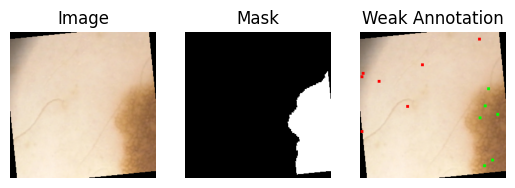

In [13]:
import matplotlib.pyplot as plt

# Sanity check
# Initialize WeakAnnotationGenerator
# weak_gen = WeakAnnotationGenerator()

images, masks = next(iter(train_loader_ph2))

mask = masks[0]  # Get the first mask
image = images[0]  # Get the first image

mask = mask.squeeze(0)

weak_gen = WeakAnnotationGenerator()

weak_mask = weak_gen.generate_annotations(mask.bool(), AnnotationType.POINTS, num_positive=6, num_negative=7)

print(weak_mask)
weak_mask_vis = visualize_annotations(image, weak_mask, AnnotationType.POINTS)

# Create a binary mask
binary_mask = torch.zeros_like(mask, dtype=torch.float)

weak_masks = []
# Set positive points in the binary mask
positive_points = weak_mask['positive_points']
for point in positive_points:
    x, y = point[0].item(), point[1].item()
    if 0 <= x < binary_mask.size(1) and 0 <= y < binary_mask.size(0):
        binary_mask[y, x] = 1  # Set pixel to 1 at the positive point

weak_masks.append(binary_mask)  # Add the binary mask for this image


fig, axes = plt.subplots(1, 3)

# Display the image
axes[0].imshow(image.permute(1, 2, 0))  # Permute to (H, W, C) for imshow
axes[0].set_title('Image')
axes[0].axis('off')  # Turn off axis ticks and labels

# Display the mask
axes[1].imshow(mask.squeeze(), cmap='gray')  # Squeeze to remove channel dimension if necessary
axes[1].set_title('Mask')
axes[1].axis('off')

axes[2].imshow(weak_mask_vis.permute(1, 2, 0), cmap='gray')  # Squeeze to remove channel dimension if necessary
axes[2].set_title('Weak Annotation')
axes[2].axis('off')

# Show the plot
plt.show()




In [51]:
# Set up model and parameters
model_unet = UNET(in_channels=3, out_channels=1).to(device)
epoch = 1000
#criterion = bce_loss
#criterion = weighted_bce_loss
#criterion = focal_loss
lr = 1e-4
weight_decay = 1e-4

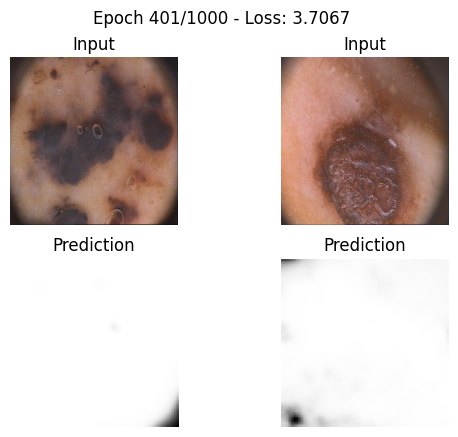

In [ ]:
# Train UNet
torch.cuda.empty_cache()
trainUNet(model_unet, optim.AdamW(model_unet.parameters(), lr, weight_decay=weight_decay, betas=(0.9, 0.999)), epoch, train_loader, test_loader, device)

In [ ]:
# Assess UNet

# Collections for final metrics
visuals = []
predictions = []
ground_truths = []

# Load a batch from the validation loader
#X_test, Y_test = next(iter(test_loader))
for batch in iter(test_loader):
  X_test, Y_test = batch

  model_unet.eval() # Set the model to evaluation mode

  Y_hat = F.sigmoid(model_unet(X_test.to(device))).detach().cpu()
  Y_hat = (Y_hat > 0.5).float() # Binarization for the pred mask

  # Clear previous plots
  clear_output(wait=True)

  for k in range(X_test.shape[0]):
    X_cropped = center_crop(X_test[k].cpu(), (68, 68))
    Y_cropped = center_crop(Y_test[k].cpu(), (68, 68))

    visuals.append(X_test[k].cpu().permute(1, 2, 0).numpy())
    ground_truths.append(Y_cropped.numpy())
    predictions.append(Y_hat[k].cpu().numpy())

    # Some Visualizations of Results
    if (k * 4 + 1 ) < 9:
      plt.subplot(2, 4, k * 4 + 1)
      plt.imshow(np.rollaxis(X_test[k].cpu().numpy(), 0, 3), cmap='gray')
      plt.title('Real')
      plt.axis('off')

      plt.subplot(2, 4, k * 4 + 2)
      plt.imshow(np.rollaxis(X_cropped.numpy(), 0, 3), cmap='gray')
      plt.title('Real Cropped')
      plt.axis('off')

      plt.subplot(2, 4, k * 4 + 3)
      plt.imshow(Y_cropped[0].numpy(), cmap='gray')
      plt.title('Label Cropped')
      plt.axis('off')

      plt.subplot(2, 4, k * 4 + 4)
      plt.imshow(Y_hat[k, 0].cpu().numpy(), cmap='gray')
      plt.title('Output')
      plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
metrics_list = ["sensitivity", "specificity", "accuracy", "iou", "dice"]
metrics_vals = np.zeros(len(metrics_list))

for idx, visual in enumerate(visuals):
  print(f"Image {idx + 1}")
  plt.imshow(visual, cmap='gray')
  plt.axis('off')
  for metric_idx, metric in enumerate(metrics_list):
    metric_val = Metrics(metric, predictions[idx], center_crop(ground_truths[idx], (68, 68)))
    metrics_vals[metric_idx] += metric_val
    print(f"{metric}: {metric_val}")

metrics_vals /= len(visuals)
print(metrics_vals.round(4))